In [ ]:
%pip install -q MetaTrader5 statsmodels arch matplotlib

In [15]:
# =====================================================================
#  CONFIG  - the ONLY cell you need to edit.   (Open MT5 and log in to your demo account first.)
# =====================================================================
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from arch import arch_model
import MetaTrader5 as mt5
from IPython.display import display, clear_output

# ---- MT5 ----
MT5_SYMBOL = "BTCUSDm"          # EXACTLY as shown in MT5 > Market Watch (e.g. "BTCUSDm")
MT5_LOGIN, MT5_PASSWORD, MT5_SERVER = None, None, None    # None = use the account already logged in inside MT5

# ---- model ----
HORIZON_MIN = 15                # forecast the move over the next N minutes (5 to 30 makes sense for scalping)
TRAIN_DAYS  = 20                # trading days of 1-minute bars used to fit the model
TEST_DAYS   = 10                # trading days used by the Step 4 check (walk-forward test)

# ---- extra inputs: each one can be switched on or off. Step 4 tests every enabled input against the plain model ----
USE_TICK_VOLUME = True      # how busy the last 15 minutes were (price updates per bar) vs usual for this time of day. Free from MT5.
USE_RANGE       = False     # measure volatility from each bar's high-low range (less noisy) instead of only the close-to-close move
USE_NEWS        = False     # flag forecast windows that contain a scheduled news release (needs the event times below)
NEWS_FILE       = "news_events.csv"   # text file, one event time per line in UTC (first line: time). Used when USE_NEWS = True
NEWS_EXTRA      = []                  # or type them here, e.g. ["2026-11-06 13:30", "2026-11-12 13:30"]  (UTC)
BROKER_UTC_OFFSET_HOURS = 0           # broker server time minus UTC (Exness = 0; many brokers use +2 or +3)

# ---- live loop ----
POLL_SECONDS    = 5             # screen refresh
REFIT_EVERY_MIN = 60            # refit the model every N minutes
LOG_ROWS        = 10            # rows in the live table

# ---- fixed design (no need to change) ----
W_SHORT, W_MID, W_LONG = 15, 60, 1380    # HAR parts: last 15 min, last hour, last trading day (~23 h; Step 1 shortens it if your symbol trades fewer hours)
BUCKET = 15                              # time-of-day pattern measured in 15-minute slots
EPS = 1e-3

In [16]:
# ---------------------------------------------------------------------
#  Helper functions (run once, nothing to edit)
# ---------------------------------------------------------------------
def mt5_connect():
    ok = mt5.initialize() if MT5_LOGIN is None else mt5.initialize(login=MT5_LOGIN, password=MT5_PASSWORD, server=MT5_SERVER)
    if not ok:
        raise RuntimeError(f"MT5 initialize failed: {mt5.last_error()}  -> is MT5 open and logged in to your demo account?")
    if not mt5.symbol_select(MT5_SYMBOL, True):
        raise RuntimeError(f"Symbol '{MT5_SYMBOL}' not found: {mt5.last_error()}  -> copy the exact name from Market Watch")
    print("Connected to MT5:", getattr(mt5.account_info(), "server", "?"), "| symbol:", MT5_SYMBOL)


def mt5_bars(n):
    """Last n CLOSED 1-minute bars (position 1 skips the still-forming bar): close, high, low, tick volume.
    Index = broker server time."""
    rates = mt5.copy_rates_from_pos(MT5_SYMBOL, mt5.TIMEFRAME_M1, 1, n)
    if rates is None or len(rates) == 0:
        raise RuntimeError(f"No bars returned: {mt5.last_error()}")
    d = pd.DataFrame(rates)
    d["time"] = pd.to_datetime(d["time"], unit="s")
    d = d.set_index("time").sort_index()
    d = d[~d.index.duplicated(keep="last")]
    return d[["close", "high", "low", "tick_volume"]].dropna(subset=["close"])


def clean_returns(close):
    """1-minute log returns; the return across any gap (weekend, daily break) is dropped."""
    r = np.log(close).diff()
    gap = close.index.to_series().diff() > pd.Timedelta(minutes=5)
    return r[~gap].dropna()


def make_bars(raw):
    """Model input from raw MT5 bars: r = 1-minute log return (gaps removed), pk = variance from the high-low range
    (Parkinson), v = tick volume."""
    B = pd.DataFrame({"r": clean_returns(raw["close"])})
    hl = np.log(raw["high"] / raw["low"]).where(raw["low"] > 0)
    B["pk"] = (hl ** 2 / (4 * np.log(2))).reindex(B.index)
    B["v"] = raw["tick_volume"].astype(float).reindex(B.index)
    return B


def slot(index):
    """15-minute slot of the day (0 ... 95) for each timestamp."""
    return ((index.hour * 60 + index.minute) // BUCKET).to_numpy()


def _smooth(m):
    return (m.shift(1, fill_value=m.iloc[-1]) + 2 * m + m.shift(-1, fill_value=m.iloc[0])) / 4


def tod_factor(r):
    """Time-of-day pattern: how busy each 15-minute slot usually is, relative to the average minute (1.0 = average).
    Built from mean absolute returns (robust to spikes), lightly smoothed with the neighbouring slots."""
    m = r.abs().groupby(slot(r.index)).mean().reindex(range(1440 // BUCKET)).interpolate(limit_direction="both")
    m = _smooth(m)
    return (m / r.abs().mean()) ** 2


def vol_profile(v):
    """Same idea for tick volume: how many price updates each 15-minute slot usually has (1.0 = the average minute)."""
    m = v.groupby(slot(v.index)).mean().reindex(range(1440 // BUCKET)).interpolate(limit_direction="both")
    return _smooth(m) / v.mean()


def future_slots_sum(index, s, h):
    """Sum of the time-of-day factor over the next h minutes after each timestamp (clock based)."""
    mins = (index.hour * 60 + index.minute).to_numpy()
    sv, out = s.to_numpy(), np.zeros(len(index))
    for k in range(1, h + 1):
        out += sv[((mins + k) % 1440) // BUCKET]
    return out


# ---------------------------------------------------------------------
#  Extra inputs: notes, news times
# ---------------------------------------------------------------------
_SEEN = set()
_NEWS = {}


def warn_once(msg):
    if msg not in _SEEN:
        _SEEN.add(msg)
        print("NOTE:", msg)


def load_news():
    """Scheduled news times from NEWS_FILE and NEWS_EXTRA, converted from UTC to broker time.
    Returns a sorted numpy array of minutes (datetime64[m]) or None if there are none."""
    items = [str(x) for x in NEWS_EXTRA]
    if os.path.exists(NEWS_FILE):
        with open(NEWS_FILE, encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if line and not line.startswith("#"):
                    items.append(line.split(",")[0].strip())
    ts = pd.to_datetime(pd.Series([x for x in items if x.lower() != "time"]), errors="coerce")
    if ts.isna().any():
        print(f"NOTE: {int(ts.isna().sum())} news line(s) could not be read as a date and were skipped.")
    ts = ts.dropna()
    if len(ts) and ts.dt.tz is not None:
        ts = ts.dt.tz_convert("UTC").dt.tz_localize(None)
    ts = (ts + pd.Timedelta(hours=BROKER_UTC_OFFSET_HOURS)).dt.floor("min").drop_duplicates().sort_values()
    return ts.to_numpy().astype("datetime64[m]") if len(ts) else None


def news_times(reload=False):
    if reload or "t" not in _NEWS:
        _NEWS["t"] = load_news()
    if _NEWS["t"] is None:
        raise RuntimeError(f"USE_NEWS is on but no news times were found. Put them in '{NEWS_FILE}' (one UTC time per line, "
                           f"first line: time) or in NEWS_EXTRA in the config cell, or set USE_NEWS = False.")
    return _NEWS["t"]


def news_flag(index, events, h):
    """1 if a scheduled news time falls inside the next h minutes after each bar, else 0. Known in advance, no look-ahead."""
    t = index.to_numpy().astype("datetime64[m]")
    j = np.searchsorted(events, t, side="right")                   # first event strictly after the bar
    gap = events[np.minimum(j, len(events) - 1)] - t
    return pd.Series(((j < len(events)) & (gap <= np.timedelta64(h, "m"))).astype(float), index=index)


# ---------------------------------------------------------------------
#  The model
# ---------------------------------------------------------------------
def har_parts(B, m):
    """Squared returns with the time-of-day pattern taken out (a), and the model inputs X: last 15 min, last hour,
    last day, plus the extra inputs that are switched on (tick volume, news)."""
    sl = slot(B.index)
    base = m.s.to_numpy()[sl] * m.scale
    a = pd.Series(B["r"].to_numpy() ** 2 / base, index=B.index)
    src = a
    if m.use_rng:                                                  # the same thing measured from the high-low range
        src = pd.Series(B["pk"].to_numpy() * m.pk_k / base, index=B.index)
    X = pd.DataFrame({"short": src.rolling(W_SHORT).mean(), "mid": src.rolling(W_MID).mean(), "long": src.rolling(W_LONG).mean()})
    if m.use_vol:                                                  # tick volume vs usual for the time of day
        va = pd.Series(B["v"].to_numpy() / m.vs.to_numpy()[sl] / m.vscale, index=B.index)
        X["vol"] = va.rolling(W_SHORT).mean()
    if m.news is not None:
        X["news"] = news_flag(B.index, m.news, m.h)
    return a, X


def ahead(x, h):
    """Sum of x over the next h rows (the target / the outcome)."""
    return x[::-1].rolling(h).sum()[::-1].shift(-1)


class IntradayHAR:
    """log-HAR-RV on 1-minute data with a time-of-day adjustment and optional extra inputs.
    Forecasts the variance of the next h minutes."""

    def __init__(self, h, use_tod=True, vol=False, rng=False, news=None):
        self.h, self.use_tod, self.use_vol, self.use_rng, self.news = h, use_tod, vol, rng, news

    def _design(self, X):
        Z = pd.DataFrame(index=X.index)
        for c in self.cols:
            Z[c] = X[c] if c == "news" else np.log(X[c] + EPS)
        return sm.add_constant(Z, has_constant="add")

    def fit(self, B):
        r = B["r"]
        if self.use_vol and not (B["v"].gt(0).mean() > 0.9):
            warn_once("Tick volume is missing (or mostly zero) for this symbol, so the tick-volume input is left out.")
            self.use_vol = False
        if self.use_rng and not (B["pk"].gt(0).mean() > 0.5):
            warn_once("The high-low range is missing or flat for this symbol, so the range input is left out.")
            self.use_rng = False
        self.s = tod_factor(r) if self.use_tod else pd.Series(1.0, index=range(1440 // BUCKET))
        self.scale = float((r ** 2).mean())
        if self.use_rng:
            self.pk_k = self.scale / float(B["pk"].mean())         # make the range measure average the same as r^2
        if self.use_vol:
            self.vs = vol_profile(B["v"])
            self.vscale = float((B["v"].to_numpy() / self.vs.to_numpy()[slot(B.index)]).mean())
        a, X = har_parts(B, self)
        y = ahead(a, self.h) / self.h
        d = pd.concat([X, y.rename("y")], axis=1).dropna().iloc[::self.h]     # non-overlapping targets
        self.cols = ["short", "mid", "long"] + (["vol"] if self.use_vol else []) + (["news"] if self.news is not None else [])
        if "news" in self.cols and d["news"].sum() < 3:
            warn_once("Too few news windows fall inside the fitting period to measure their effect, so the news input is "
                      "left out of those fits (use a longer TRAIN_DAYS or add more events).")
            self.cols.remove("news")
        self.res = sm.OLS(np.log(d["y"] + EPS), self._design(d)).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
        self.smear = float(np.mean(np.exp(self.res.resid)))                   # back-transform correction for the log
        V = self.variance(X.loc[d.index])
        z = (ahead(r, self.h).loc[d.index] / np.sqrt(V)).dropna()
        self.q68, self.q95 = float(z.abs().quantile(0.68)), float(z.abs().quantile(0.95))   # range widths from real moves
        self.n_obs, self.fitted_at = len(d), r.index[-1]
        return self

    def variance(self, X):
        """Forecast variance (log-return units) of the move over the next h minutes, for each row of X."""
        level = np.exp(self._design(X).to_numpy() @ self.res.params.to_numpy()) * self.smear
        return pd.Series(level * future_slots_sum(X.index, self.s, self.h) * self.scale, index=X.index)


def new_model(h, tod=True, vol=None, rng=None, news=None):
    """The model with the extra inputs that are switched on in the config cell (pass vol / rng / news = True or False
    to override one of them)."""
    vol = USE_TICK_VOLUME if vol is None else vol
    rng = USE_RANGE if rng is None else rng
    news = USE_NEWS if news is None else news
    return IntradayHAR(h, tod, vol, rng, news_times() if news else None)


def garch_variance(r_train, r_window, h):
    """Baseline for Step 4: GARCH(1,1)-t on 1-minute returns, variance of the next h minutes."""
    k = 1 / r_train.std()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        g = arch_model(r_train * k, mean="Zero", vol="GARCH", p=1, q=1, dist="t", rescale=False).fit(disp="off")
        gf = arch_model(r_window * k, mean="Zero", vol="GARCH", p=1, q=1, dist="t", rescale=False).fix(g.params)
    om, al, be = g.params["omega"], g.params["alpha[1]"], g.params["beta[1]"]
    p = min(al + be, 0.99999)
    wbar = om / (1 - p)
    h1 = om + al * (r_window * k).to_numpy() ** 2 + be * gf.conditional_volatility.to_numpy() ** 2
    return pd.Series((h * wbar + (h1 - wbar) * (1 - p ** h) / (1 - p)) / k ** 2, index=r_window.index)


def full_days(r, min_frac=0.7):
    """Trading days with most of a normal session: at least 70% of this symbol's typical number of bars per day.
    (A fixed bar count only suits symbols that trade ~23 h; stocks and indices trade fewer hours.)"""
    cnt = r.groupby(r.index.floor("D")).count()
    if len(cnt) == 0:
        return cnt.index
    return cnt[cnt >= max(min_frac * float(cnt.median()), 60)].index


def session_bars(r, days):
    """(normal bars per trading day, length of the 'last day' window). 24 h symbols keep 1380 minutes."""
    per_day = r.groupby(r.index.floor("D")).count()
    typical = int(per_day.loc[days].median()) if len(days) else int(per_day.median())
    return typical, (1380 if typical >= 1200 else max(typical, 4 * W_MID))


def to_ist(ts):
    return ts + pd.Timedelta(hours=5, minutes=30) - pd.Timedelta(hours=BROKER_UTC_OFFSET_HOURS)   # broker time -> India time

In [17]:
# ==============================================================================
# STEP 1: LOAD 1-MINUTE HISTORY FROM MT5 (closed bars only)
# ==============================================================================
mt5_connect()
asked = (TRAIN_DAYS + TEST_DAYS + 3) * 1440
bars = mt5_bars(asked)
mt5.shutdown()

close = bars["close"]
r = clean_returns(close)
B = make_bars(bars)                              # return, range variance and tick volume per minute
days = full_days(r)
typical, W_LONG = session_bars(r, days)          # W_LONG: the "last day" window = this symbol's normal session
print(f"{MT5_SYMBOL} M1: {len(close):,} closed bars | {close.index[0]}  ->  {close.index[-1]}  (broker time)")
print(f"Normal day: {typical:,} bars (about {typical / 60:.1f} hours of trading) -> the 'last day' window is {W_LONG:,} minutes")
print(f"Full trading days: {len(days)}  (need at least {TRAIN_DAYS + 2} to fit, {TRAIN_DAYS + TEST_DAYS} for the Step 4 test)")
if USE_TICK_VOLUME:
    v = bars["tick_volume"]
    print(f"Tick volume: median {v.median():,.0f} price updates per minute, {(v <= 0).mean():.1%} of bars empty")
if USE_NEWS:
    ev = news_times(reload=True)
    inside = int(((ev >= close.index[0].to_datetime64().astype("datetime64[m]")) &
                  (ev <= close.index[-1].to_datetime64().astype("datetime64[m]"))).sum())
    print(f"News: {len(ev)} events in your list, {inside} of them inside the loaded history "
          f"(times converted from UTC to broker time, offset {BROKER_UTC_OFFSET_HOURS:+g} h)")
    if inside < 8:
        print("-> Few events fall inside the history, so the news effect will be hard to measure: add more events or raise TRAIN_DAYS.")
if len(days) < TRAIN_DAYS + 2:
    msg = f"Not enough history: {len(days)} full trading days found, need {TRAIN_DAYS + 2}."
    if len(close) < 0.98 * asked:
        msg += (f" MT5 returned only {len(close):,} of the {asked:,} bars requested. Open this symbol's 1-minute chart,"
                f" press Home a few times (or raise Tools > Options > Charts > Max bars in chart), then run this cell again.")
    else:
        msg += " Lower TRAIN_DAYS and TEST_DAYS in the config cell."
    raise RuntimeError(msg)

Connected to MT5: Exness-MT5Trial6 | symbol: BTCUSDm
BTCUSDm M1: 47,520 closed bars | 2026-09-15 13:07:00  ->  2026-10-18 13:21:00  (broker time)
Normal day: 1,440 bars (about 24.0 hours of trading) -> the 'last day' window is 1,380 minutes
Full trading days: 32  (need at least 22 to fit, 30 for the Step 4 test)
Tick volume: median 70 price updates per minute, 0.0% of bars empty


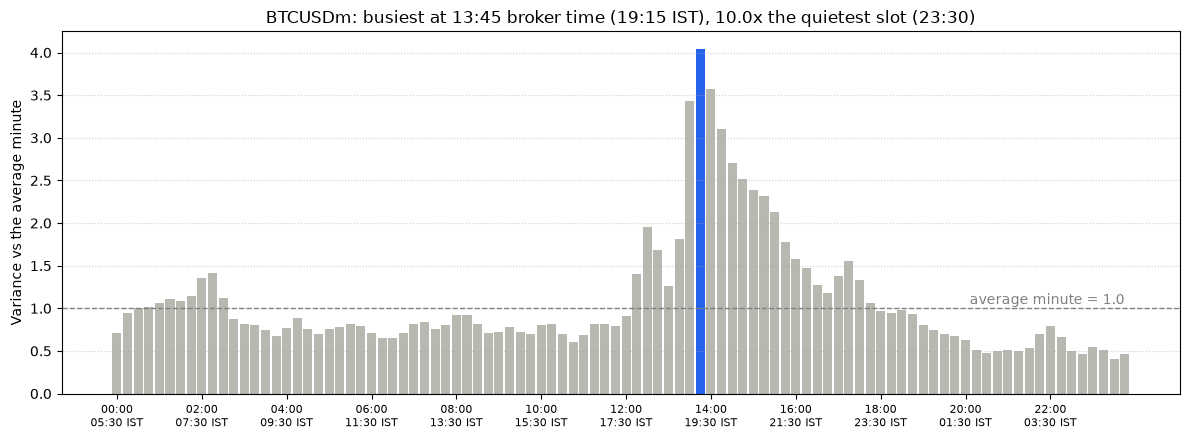

Busiest 15 minutes : 13:45 broker = 19:15 IST  ->  4.05x an average minute
Quietest 15 minutes: 23:30 broker = 05:00 IST  ->  0.41x an average minute
The model takes this pattern out before fitting and puts it back into every forecast.


In [18]:
# ==============================================================================
# STEP 2: THE TIME-OF-DAY PATTERN (how busy each 15 minutes of the day usually is)
# ==============================================================================
r_train = r[r.index >= days[-TRAIN_DAYS]]
s = tod_factor(r_train)
busiest, quietest = int(s.idxmax()), int(s.idxmin())
hm = lambda k: f"{k * BUCKET // 60:02d}:{k * BUCKET % 60:02d}"
ist = lambda k: (pd.Timestamp("2000-01-01") + pd.Timedelta(minutes=k * BUCKET + 330 - int(60 * BROKER_UTC_OFFSET_HOURS))).strftime("%H:%M")

plt.figure(figsize=(12, 4.5))
plt.bar(s.index, s.values, width=0.85, color=["#2563eb" if k == busiest else "#b8b8b0" for k in s.index])
plt.axhline(1, color="grey", linestyle="--", linewidth=1)
plt.text(len(s) - 1, 1.05, "average minute = 1.0", ha="right", color="grey")
ticks = list(range(0, len(s), 8))
plt.xticks(ticks, [f"{hm(k)}\n{ist(k)} IST" for k in ticks], fontsize=8)
plt.title(f"{MT5_SYMBOL}: busiest at {hm(busiest)} broker time ({ist(busiest)} IST), "
          f"{s.max() / s.min():.1f}x the quietest slot ({hm(quietest)})")
plt.ylabel("Variance vs the average minute"); plt.grid(axis="y", linestyle=":", alpha=0.6); plt.tight_layout(); plt.show()

print(f"Busiest 15 minutes : {hm(busiest)} broker = {ist(busiest)} IST  ->  {s.max():.2f}x an average minute")
print(f"Quietest 15 minutes: {hm(quietest)} broker = {ist(quietest)} IST  ->  {s.min():.2f}x an average minute")
print("The model takes this pattern out before fitting and puts it back into every forecast.")

In [19]:
# ==============================================================================
# STEP 3: FIT THE INTRADAY HAR-RV MODEL (log-HAR + time of day)
# ==============================================================================
B_train = B[B.index >= days[-TRAIN_DAYS]]
model = new_model(HORIZON_MIN).fit(B_train)
p = model.res.params
table = pd.DataFrame({"Coefficient": p.round(3), "t-stat": model.res.tvalues.round(2)})
names = {"short": "Last 15 min", "mid": "Last hour", "long": "Last day", "vol": "Tick volume (last 15 min)",
         "news": f"News in next {HORIZON_MIN} min"}
table.index = ["Constant"] + [names[c] for c in model.cols]
print(f"Fitted on {TRAIN_DAYS} trading days ({model.n_obs:,} non-overlapping {HORIZON_MIN}-minute periods), log scale:")
display(table)
print(f"Persistence (sum of the three weights): {p[['short', 'mid', 'long']].sum():.2f}   (closer to 1 = volatility shocks last longer)")
extra = [n for n, on in (("tick volume", model.use_vol), ("high-low range", model.use_rng),
                         ("news", "news" in model.cols)) if on]
if extra:
    print("Extra inputs used: " + ", ".join(extra) + "   (Step 4 shows whether each one actually helps)")
print(f"Range widths from real moves: 68% range = ±{model.q68:.2f} sigma, 95% range = ±{model.q95:.2f} sigma"
      f"   (a normal curve would say 1.00 and 1.96)")

a_now, X_now = har_parts(B, model)
V_now = float(model.variance(X_now.dropna().iloc[[-1]]).iloc[0])
last = float(close.iloc[-1])
print(f"\nForecast from the last closed bar ({close.index[-1]}): the next {HORIZON_MIN} minutes move about "
      f"±{last * np.sqrt(V_now):.3f} (1 sigma), 95% range {last * np.exp(-model.q95 * np.sqrt(V_now)):.3f} ... "
      f"{last * np.exp(model.q95 * np.sqrt(V_now)):.3f}")

Fitted on 20 trading days (1,880 non-overlapping 15-minute periods), log scale:


,Coefficient,t-stat
Constant,-0.210,-9.90
Last 15 min,0.255,7.04
Last hour,0.475,12.61
Last day,0.159,4.57
Tick volume (last 15 min),0.349,2.79


Persistence (sum of the three weights): 0.89   (closer to 1 = volatility shocks last longer)
Extra inputs used: tick volume   (Step 4 shows whether each one actually helps)
Range widths from real moves: 68% range = ±0.75 sigma, 95% range = ±1.93 sigma   (a normal curve would say 1.00 and 1.96)

Forecast from the last closed bar (2026-10-18 13:21:00): the next 15 minutes move about ±111.024 (1 sigma), 95% range 81581.436 ... 82009.043


In [20]:
# ==============================================================================
# STEP 4: WALK-FORWARD TEST ON YOUR DATA (fit on the past only, score on the next day, repeat)
#   compares: plain HAR + time of day | each extra input you switched on | HAR without time of day |
#             GARCH(1,1) on 1-minute bars | last-15-minutes (naive)
# ==============================================================================
H = HORIZON_MIN
BASE = "HAR + time of day"
test_days = days[-TEST_DAYS:] if len(days) >= TRAIN_DAYS + TEST_DAYS else days[TRAIN_DAYS:]
off = dict(vol=False, rng=False, news=False)
specs = [(BASE, dict(off))]                                                   # the plain model: no extra inputs
extras = [(f"HAR + {n}", {**off, k: True}) for n, k, on in
          (("tick volume", "vol", USE_TICK_VOLUME), ("range", "rng", USE_RANGE), ("news", "news", USE_NEWS)) if on]
specs += extras
if len(extras) > 1:
    specs.append(("HAR + all enabled inputs", {}))                            # {} = whatever the config cell switches on
specs.append(("HAR, no time of day", {**off, "tod": False}))
rows = []
for day in test_days:
    past = days[days < day][-TRAIN_DAYS:]
    rtr = B[(B.index >= past[0]) & (B.index < day)]
    win = B[(B.index >= past[0]) & (B.index < day + pd.Timedelta(days=1))]
    is_test, rv_next, move_next = win.index >= day, ahead(win["r"] ** 2, H), ahead(win["r"], H)
    cands = {}
    for name, kw in specs:
        m = new_model(H, **kw).fit(rtr)
        cands[name] = m.variance(har_parts(win, m)[1])
    cands["GARCH(1,1) on 1-min bars"] = garch_variance(rtr["r"], win["r"], H)
    cands[f"Naive (last {H} min)"] = (win["r"] ** 2).rolling(H).sum()
    for name, V in cands.items():
        z = (move_next / np.sqrt(V))[~is_test].replace([np.inf, -np.inf], np.nan).dropna()
        z = z[z.index.minute % H == 0].abs()                      # range widths from this model's own past moves
        rows.append(pd.DataFrame({"model": name, "V": V, "rv": rv_next, "move": move_next,
                                  "q68": z.quantile(0.68), "q95": z.quantile(0.95)})[is_test])
R = pd.concat(rows).dropna()
R = R[(R.V > 0) & (R.rv > 0) & (R.index.minute % H == 0)]        # non-overlapping test periods
R["Session (broker time)"] = pd.cut(R.index.hour, [-1, 6, 12, 19, 23], labels=["Asia 00-07", "Europe 07-13", "US 13-20", "Late 20-24"])

def score(g):
    x = g.rv / g.V
    return pd.Series({"QLIKE (lower = better)": (x - np.log(x) - 1).mean(),
                      "Correlation with real": np.corrcoef(np.log(g.V), np.log(g.rv))[0, 1],
                      "Inside 68% range": (g.move.abs() <= g.q68 * np.sqrt(g.V)).mean(),
                      "Inside 95% range": (g.move.abs() <= g.q95 * np.sqrt(g.V)).mean()})

summary = R.groupby("model").apply(score).sort_values("QLIKE (lower = better)")
print(f"{len(test_days)} test days ({test_days[0].date()} to {test_days[-1].date()}), {R.groupby('model').size().iloc[0]:,} "
      f"non-overlapping {H}-minute periods per model:")
shown = summary.copy()
shown["QLIKE (lower = better)"] = shown["QLIKE (lower = better)"].map("{:.3f}".format)
shown["Correlation with real"] = shown["Correlation with real"].map("{:.2f}".format)
for col in ["Inside 68% range", "Inside 95% range"]:
    shown[col] = shown[col].map("{:.0%}".format)
display(shown)
by_sess = R.groupby(["model", "Session (broker time)"], observed=True).apply(
    lambda g: (g.move.abs() <= g.q95 * np.sqrt(g.V)).mean()).unstack()
print("\n95% range: how often the real move stayed inside, by session (target 95% everywhere):")
display(by_sess.apply(lambda col: col.map("{:.0%}".format)))
best = summary.index[0]
print(f"\nBest forecaster on your data: {best}.")

if extras:                                                        # did each extra input beat the plain model?
    x = R.rv / R.V
    day_q = (x - np.log(x) - 1).groupby([R["model"], R.index.floor("D")]).mean().unstack(0)
    ev_days = pd.DatetimeIndex(news_times()).floor("D").unique() if USE_NEWS else []
    print(f"\nDid each extra input help? (compared with '{BASE}', lower QLIKE = better, day by day)")
    for name, _ in extras + ([("HAR + all enabled inputs", {})] if len(extras) > 1 else []):
        gain, scope = day_q[BASE] - day_q[name], ""
        if name == "HAR + news":                                  # news can only matter on days that have a release
            gain, scope = gain[gain.index.isin(ev_days)], " with a news release"
            if len(gain) == 0:
                print(f"  {name:<26s} no test day has a news release in your list, so it cannot be judged")
                continue
        verdict = "helped" if gain.mean() > 0 and (gain > 0).mean() >= 0.6 else \
                  "hurt" if gain.mean() < 0 and (gain < 0).mean() >= 0.6 else "no clear difference"
        print(f"  {name:<26s} better on {int((gain > 0).sum())} of {len(gain)} test days{scope}, "
              f"average gain {gain.mean():+.4f}  -> {verdict}")
    print("  With only a few test days a small gain can be luck: keep an input only if it helps on most days, "
          "and set the ones that did not help to False in the config cell.")

10 test days (2026-10-08 to 2026-10-17), 949 non-overlapping 15-minute periods per model:


,QLIKE (lower = better),Correlation with real,Inside 68% range,Inside 95% range
model,,,,
HAR + tick volume,0.393,0.80,69%,95%
HAR + time of day,0.398,0.80,69%,94%
"HAR, no time of day",0.399,0.80,69%,95%
"GARCH(1,1) on 1-min bars",0.417,0.79,69%,95%
Naive (last 15 min),0.576,0.76,67%,94%



95% range: how often the real move stayed inside, by session (target 95% everywhere):


Session (broker time),Asia 00-07,Europe 07-13,US 13-20,Late 20-24
model,,,,
"GARCH(1,1) on 1-min bars",94%,95%,95%,95%
HAR + tick volume,94%,95%,94%,95%
HAR + time of day,94%,95%,94%,95%
"HAR, no time of day",94%,95%,94%,95%
Naive (last 15 min),94%,95%,94%,94%



Best forecaster on your data: HAR + tick volume.

Did each extra input help? (compared with 'HAR + time of day', lower QLIKE = better, day by day)
  HAR + tick volume          better on 6 of 10 test days, average gain +0.0049  -> helped
  With only a few test days a small gain can be luck: keep an input only if it helps on most days, and set the ones that did not help to False in the config cell.


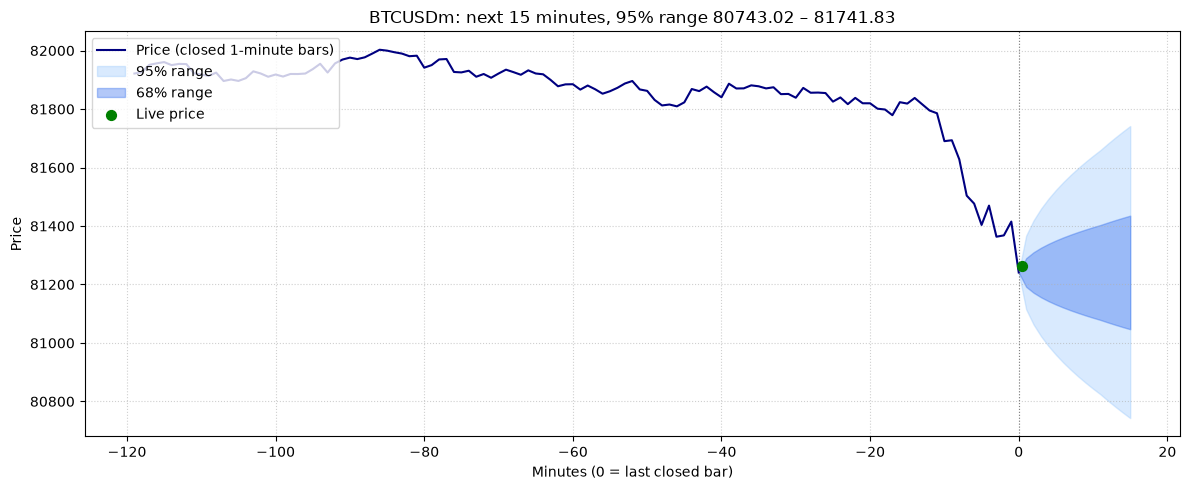

Refreshed at 19:04:53 (this computer)   |   model fitted on data up to 2026-10-18 13:21:00 (refits every 60 min)
BTCUSDm M1  last closed bar: 2026-10-18 13:33:00 broker = 19:03 IST   close: 81240.89
LIVE price : 81263.39   (bid 81260.19 / ask 81266.59, spread 6.40)
Spread check: the spread is 2% of a typical 15-minute move (1 sigma) - the higher this is, the more of each move the spread eats
Next 15 min (from last close): typical move ±259.33 (1 sigma)  |  68% range 81046.92 – 81435.33  |  95% range 80743.02 – 81741.83
Time of day : the next 15 minutes are usually 3.6x as busy as an average minute
Market now  : the last 15 minutes were 1.7x as active as usual for this time of day -> ACTIVE
Extra inputs: tick volume
Tick volume : the last 15 minutes had 1.1x the usual number of price updates for this time of day
Tracker: the first check comes 15 minutes after the first forecast ...

Last 10 closed minutes (Result = where the real move ended 15 minutes later):


,Close,1 sigma (15 min),95% low,95% high,Busy (time of day),Activity now,Result
Bar time,,,,,,,
2026-10-18 13:33:00,81240.89,259.33,80743.02,81741.83,3.6x,1.7x,pending
2026-10-18 13:32:00,81415.05,234.73,80964.27,81868.34,3.6x,1.2x,pending
2026-10-18 13:31:00,81367.88,232.04,80922.26,81815.95,3.5x,1.3x,pending
2026-10-18 13:30:00,81363.30,229.41,80922.72,81806.28,3.5x,1.3x,pending
2026-10-18 13:29:00,81469.68,214.80,81057.08,81884.38,3.4x,1.1x,pending
2026-10-18 13:28:00,81403.58,203.41,81012.81,81796.23,3.3x,1.0x,pending
2026-10-18 13:27:00,81476.50,189.78,81111.86,81842.78,3.2x,0.9x,pending
2026-10-18 13:26:00,81503.74,183.08,81151.95,81857.06,3.1x,0.9x,pending
2026-10-18 13:25:00,81627.82,151.67,81336.26,81920.42,3.0x,0.5x,pending


In [ ]:
# ---------------------------------------------------------------------
#  MT5: LIVE loop - intraday HAR-RV for scalping (closed 1-minute bars only)
#   - every new closed minute: forecast how far price can move in the next HORIZON_MIN minutes
#   - the model is refitted every REFIT_EVERY_MIN minutes on the last TRAIN_DAYS days
#   - the screen refreshes every POLL_SECONDS with the live price
#   - a tracker checks every forecast HORIZON_MIN minutes later: did the real move stay inside the range?
#  Stop with the notebook's stop button.
# ---------------------------------------------------------------------
LIVE_LOG = {}                    # one row per closed minute, newest last
PENDING = []                     # forecasts waiting for their outcome
TRACK = {"n": 0, "in68": 0, "in95": 0}


def fit_live():
    global W_LONG
    c = mt5_bars((TRAIN_DAYS + 3) * 1440)
    Bl = make_bars(c)
    dd = full_days(Bl["r"])
    W_LONG = session_bars(Bl["r"], dd)[1]            # "last day" window for this symbol's session length
    return new_model(HORIZON_MIN).fit(Bl[Bl.index >= dd[-min(TRAIN_DAYS, len(dd))]])


def forecast_now(m, tail):
    """Forecast from the last closed bar: variance of the next h minutes + how it builds minute by minute."""
    a, X = har_parts(make_bars(tail), m)
    x_last = X.iloc[[-1]]
    V = float(m.variance(x_last).iloc[0])
    t = tail.index[-1]
    mins = t.hour * 60 + t.minute
    s_next = np.array([m.s.iloc[((mins + k) % 1440) // BUCKET] for k in range(1, m.h + 1)])
    path = V * np.cumsum(s_next) / s_next.sum()                     # variance builds up with the time-of-day pattern
    busy = float(s_next.mean())                                       # next h minutes vs an average minute
    activity = float(x_last["short"].iloc[0])                         # last 15 minutes vs usual for that time of day
    ext = {}
    if m.use_vol:
        ext["vol"] = float(x_last["vol"].iloc[0])                     # tick volume vs usual for this time of day
    if m.news is not None:
        tt = t.to_datetime64().astype("datetime64[m]")
        j = int(np.searchsorted(m.news, tt, side="right"))
        ext["news"] = None if j >= len(m.news) else (pd.Timestamp(m.news[j]), int((m.news[j] - tt) / np.timedelta64(1, "m")))
    return V, path, busy, activity, ext


def check_outcomes(tail):
    """Score forecasts whose h minutes have now passed."""
    pos = {t: i for i, t in enumerate(tail.index)}
    keep = []
    for f in PENDING:
        i = pos.get(f["time"])
        if i is None or i + f["h"] >= len(tail):
            keep.append(f); continue
        t_end = tail.index[i + f["h"]]
        if t_end - f["time"] > pd.Timedelta(minutes=f["h"] + 5):      # a gap in between: not a fair test, skip
            continue
        move = abs(np.log(tail.iloc[i + f["h"]] / f["close"]))
        in68, in95 = move <= f["q68"] * np.sqrt(f["V"]), move <= f["q95"] * np.sqrt(f["V"])
        TRACK["n"] += 1; TRACK["in68"] += int(in68); TRACK["in95"] += int(in95)
        if f["time"] in LIVE_LOG:
            LIVE_LOG[f["time"]]["Result"] = "inside 68%" if in68 else "inside 95%" if in95 else "OUTSIDE 95%"
    PENDING[:] = keep


def get_tick():
    tick = mt5.symbol_info_tick(MT5_SYMBOL)
    if tick is None or tick.bid <= 0:
        return None
    return {"bid": tick.bid, "ask": tick.ask, "live": (tick.bid + tick.ask) / 2, "time": pd.to_datetime(tick.time, unit="s")}


def render(m, tail, V, path, busy, activity, ext, d, stale):
    last, t = float(tail.iloc[-1]), tail.index[-1]
    sd = np.sqrt(V)
    lo68, hi68 = last * np.exp(-m.q68 * sd), last * np.exp(m.q68 * sd)
    lo95, hi95 = last * np.exp(-m.q95 * sd), last * np.exp(m.q95 * sd)
    tk = get_tick()

    # ---- chart first ----
    hist = tail.iloc[-120:]
    xh = np.arange(-len(hist) + 1, 1)
    xf = np.arange(0, m.h + 1)
    sp = np.sqrt(np.r_[0, path])
    plt.figure(figsize=(12, 5))
    plt.plot(xh, hist.values, color="navy", label="Price (closed 1-minute bars)")
    plt.fill_between(xf, last * np.exp(-m.q95 * sp), last * np.exp(m.q95 * sp), color="#93c5fd", alpha=0.35, label="95% range")
    plt.fill_between(xf, last * np.exp(-m.q68 * sp), last * np.exp(m.q68 * sp), color="#2563eb", alpha=0.35, label="68% range")
    if tk is not None and not stale:
        plt.scatter([0.5], [tk["live"]], color="green", s=50, zorder=5, label="Live price")
    plt.axvline(0, color="grey", linewidth=0.8, linestyle=":")
    plt.title(f"{MT5_SYMBOL}: next {m.h} minutes, 95% range {lo95:.{d}f} – {hi95:.{d}f}")
    plt.xlabel("Minutes (0 = last closed bar)"); plt.ylabel("Price")
    plt.grid(True, linestyle=":", alpha=0.6); plt.legend(loc="upper left"); plt.tight_layout(); plt.show(); plt.close()

    # ---- live text BELOW the chart ----
    mood = "ACTIVE" if activity > 1.5 else "CALM" if activity < 0.67 else "NORMAL"
    print(f"Refreshed at {time.strftime('%H:%M:%S')} (this computer)   |   model fitted on data up to {m.fitted_at} "
          f"(refits every {REFIT_EVERY_MIN} min)")
    print(f"{MT5_SYMBOL} M1  last closed bar: {t} broker = {to_ist(t):%H:%M} IST   close: {last:.{d}f}")
    if tk is None:
        print("Live price: not available right now")
    elif stale:
        print(f"Live price: {tk['live']:.{d}f}  (no new bar for over 3 minutes - market closed or feed paused?)")
    else:
        spread = tk["ask"] - tk["bid"]
        print(f"LIVE price : {tk['live']:.{d}f}   (bid {tk['bid']:.{d}f} / ask {tk['ask']:.{d}f}, spread {spread:.{d}f})")
        print(f"Spread check: the spread is {spread / (last * sd):.0%} of a typical {m.h}-minute move (1 sigma) "
              f"- the higher this is, the more of each move the spread eats")
    print(f"Next {m.h} min (from last close): typical move ±{last * sd:.{d}f} (1 sigma)  |  "
          f"68% range {lo68:.{d}f} – {hi68:.{d}f}  |  95% range {lo95:.{d}f} – {hi95:.{d}f}")
    print(f"Time of day : the next {m.h} minutes are usually {busy:.1f}x as busy as an average minute")
    print(f"Market now  : the last 15 minutes were {activity:.1f}x as active as usual for this time of day -> {mood}")
    used = [n for n, on in (("tick volume", m.use_vol), ("high-low range", m.use_rng), ("news", m.news is not None)) if on]
    if used:
        print("Extra inputs: " + ", ".join(used))
    if "vol" in ext:
        print(f"Tick volume : the last 15 minutes had {ext['vol']:.1f}x the usual number of price updates for this time of day")
    if m.news is not None:
        nx = ext.get("news")
        if nx is None:
            print(f"News        : no event left in your list - add the coming releases to {NEWS_FILE}, or the news input does nothing")
        elif nx[1] <= 24 * 60:
            print(f"News        : next scheduled event {nx[0]:%Y-%m-%d %H:%M} broker time (in {nx[1]} min)"
                  + ("  <- inside the forecast window" if nx[1] <= m.h else ""))
        else:
            print(f"News        : next scheduled event is {nx[0]:%Y-%m-%d %H:%M} broker time (more than 24 h away)")
    if TRACK["n"]:
        n = TRACK["n"]
        print(f"Tracker ({n} forecasts checked): real move inside 68% range {TRACK['in68'] / n:.0%} (target 68%)  |  "
              f"inside 95% range {TRACK['in95'] / n:.0%} (target 95%)")
    else:
        print(f"Tracker: the first check comes {m.h} minutes after the first forecast ...")
    rows = list(LIVE_LOG.values())[-LOG_ROWS:]
    print(f"\nLast {len(rows)} closed minutes (Result = where the real move ended {m.h} minutes later):")
    display(pd.DataFrame(rows).set_index("Bar time").iloc[::-1])


def run_live():
    mt5_connect()
    info = mt5.symbol_info(MT5_SYMBOL)
    d = int(getattr(info, "digits", 3) or 3)
    print(f"Fitting the model on the last {TRAIN_DAYS} trading days ...")
    m = fit_live()
    last_seen, state, last_new = None, None, time.time()
    try:
        while True:
            tail = mt5_bars(W_LONG + 400)
            px = tail["close"]
            t = px.index[-1]
            if t != last_seen:                                          # a NEW minute has closed
                last_seen, last_new = t, time.time()
                if t - m.fitted_at >= pd.Timedelta(minutes=REFIT_EVERY_MIN):
                    print("Refitting the model on fresh data ..."); m = fit_live()
                check_outcomes(px)
                V, path, busy, activity, ext = forecast_now(m, tail)
                last = float(px.iloc[-1])
                PENDING.append({"time": t, "close": last, "V": V, "q68": m.q68, "q95": m.q95, "h": m.h})
                LIVE_LOG[t] = {"Bar time": t, "Close": round(last, d), f"1 sigma ({m.h} min)": round(last * np.sqrt(V), d),
                               "95% low": round(last * np.exp(-m.q95 * np.sqrt(V)), d),
                               "95% high": round(last * np.exp(m.q95 * np.sqrt(V)), d),
                               "Busy (time of day)": f"{busy:.1f}x", "Activity now": f"{activity:.1f}x", "Result": "pending"}
                while len(LIVE_LOG) > 500:
                    LIVE_LOG.pop(next(iter(LIVE_LOG)))
                state = (V, path, busy, activity, ext)
            clear_output(wait=True)
            render(m, px, *state, d, time.time() - last_new > 180)
            time.sleep(POLL_SECONDS)
    except KeyboardInterrupt:
        print("Stopped.")
    finally:
        mt5.shutdown()


run_live()